# T11 — Exploratory Data Analysis | HalluCheck
**Angelica | Group 01**

**Objective:** Use the cleaned response dataset and engineered features to create four Matplotlib charts, save each PNG in `results/figures/`, and provide one evidence-based takeaway for each chart.

**Required files:** `responses_clean.csv` (T04) and `features.csv` (T07). In Google Colab, run the cells in order and upload both files when prompted. The notebook calculates findings from the uploaded data; review the results before submitting. 


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FIG_DIR = Path("results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Charts will be saved to:", FIG_DIR)

Charts will be saved to: results/figures


## 1. Upload the T04 and T07 CSV files
Google Colab will open a file picker. Upload both `responses_clean.csv` and `features.csv`. You do not need the larger raw RAGTruth files.


In [4]:
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Not in Colab: place responses_clean.csv and features.csv in this notebook folder.")

clean_path = Path("responses_clean.csv")
feature_path = Path("features.csv")
for path in (clean_path, feature_path):
    if not path.exists():
        raise FileNotFoundError(f"Missing {path.name}: upload both T04 and T07 CSV files.")

clean = pd.read_csv(clean_path, low_memory=False)
features = pd.read_csv(feature_path, low_memory=False)
print("Cleaned responses:", clean.shape)
print("Feature data:", features.shape)
print("Clean columns:", list(clean.columns))
print("Feature columns:", list(features.columns))

Saving features.csv to features.csv
Cleaned responses: (17617, 13)
Feature data: (17617, 18)
Clean columns: ['id', 'source_id', 'model', 'temperature', 'labels', 'split', 'quality', 'response', 'task_type', 'source', 'source_info', 'prompt', 'hallucinated']
Feature columns: ['id', 'source_id', 'split', 'hallucinated', 'word_overlap', 'missing_numbers', 'missing_names', 'answer_length', 'length_ratio', 'task_type_Data2txt', 'task_type_QA', 'task_type_Summary', 'model_gpt-3.5-turbo-0613', 'model_gpt-4-0613', 'model_llama-2-13b-chat', 'model_llama-2-70b-chat', 'model_llama-2-7b-chat', 'model_mistral-7B-instruct']


## 2. Join and validate the datasets
Join the datasets using the unique response `id`, rather than assuming the rows appear in the same order. Each cleaned response should match exactly one engineered feature row.


In [5]:
if "id" not in clean or "id" not in features:
    raise ValueError("Both CSV files must have an id column for a safe join.")
if clean["id"].isna().any() or features["id"].isna().any():
    raise ValueError("Response IDs must not be missing.")
if clean["id"].duplicated().any() or features["id"].duplicated().any():
    raise ValueError("IDs must be unique before joining. Check the CSV files.")

# Keep the cleaned dataset label, model, and task type as the source of truth.
feature_columns = ["id", "word_overlap", "missing_numbers", "missing_names", "answer_length", "length_ratio"]
missing = [c for c in feature_columns if c not in features.columns]
if missing:
    raise ValueError(f"Features CSV is missing required columns: {missing}")
for col in ("hallucinated", "model", "task_type"):
    if col not in clean.columns:
        raise ValueError(f"Cleaned CSV is missing required column: {col}")

df = clean[["id", "hallucinated", "model", "task_type"]].merge(
    features[feature_columns], on="id", how="inner", validate="one_to_one"
)
if len(df) != len(clean) or len(df) != len(features):
    raise ValueError(f"Join did not match all rows: clean={len(clean)}, features={len(features)}, joined={len(df)}")
df["hallucinated"] = pd.to_numeric(df["hallucinated"], errors="raise")
if not set(df["hallucinated"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Expected binary 0/1 hallucinated labels.")
if df["hallucinated"].isna().any():
    raise ValueError("hallucinated has missing labels")
print("Matched rows:", len(df), "| Hallucination prevalence:", f"{df.hallucinated.mean():.1%}")
display(df.head(3))

Matched rows: 17617 | Hallucination prevalence: 43.4%


,id,hallucinated,model,task_type,word_overlap,missing_numbers,missing_names,answer_length,length_ratio
0,0,0,gpt-4-0613,Summary,0.863636,0,2,110,0.235546
1,1,0,gpt-3.5-turbo-0613,Summary,0.812500,0,3,128,0.274090
2,2,1,mistral-7B-instruct,Summary,0.792453,1,1,159,0.340471


## 3. Bar chart: Hallucination rate by model
The hallucination rate is the proportion of responses labeled `hallucinated = 1` for each model. These are **descriptive rates for this dataset**, not controlled estimates of overall model reliability. Differences in task composition may influence the comparisons.


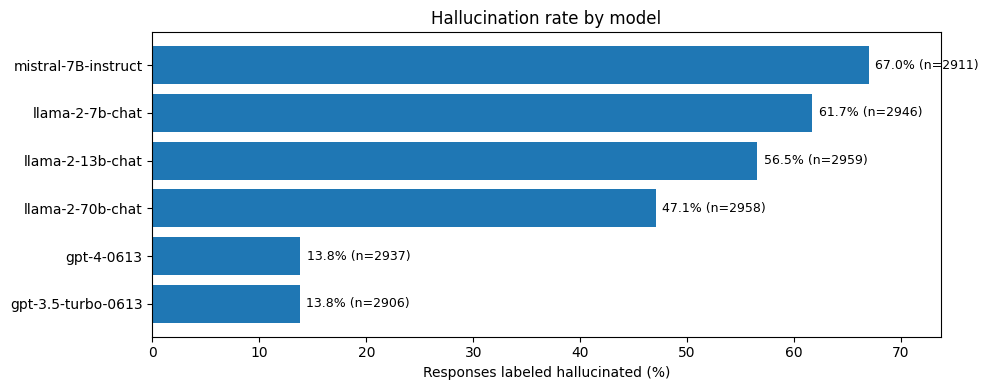

**Takeaway:** In this dataset, mistral-7B-instruct has the highest observed hallucination rate (67.0%, n=2,911), while gpt-3.5-turbo-0613 has the lowest (13.8%, n=2,906). These descriptive rates may be affected by differences in task composition.

In [6]:
model_stats = df.groupby("model", dropna=False)["hallucinated"].agg(rate="mean", n="size").sort_values("rate", ascending=False)
fig, ax = plt.subplots(figsize=(10, max(4, len(model_stats)*0.55)))
ax.barh(model_stats.index.astype(str), model_stats["rate"] * 100)
ax.invert_yaxis()
ax.set(xlabel="Responses labeled hallucinated (%)", title="Hallucination rate by model")
ax.set_xlim(0, max(5, model_stats["rate"].max()*110))
for i, (rate, count) in enumerate(zip(model_stats["rate"], model_stats["n"])):
    ax.text(rate*100+0.6, i, f"{rate:.1%} (n={count})", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR/"t11_hallucination_rate_by_model.png", dpi=180, bbox_inches="tight")
plt.show()
hi, lo = model_stats.iloc[0], model_stats.iloc[-1]
model_takeaway = (f"In this dataset, {model_stats.index[0]} has the highest observed hallucination rate "
                  f"({hi.rate:.1%}, n={int(hi.n):,}), while {model_stats.index[-1]} has the lowest "
                  f"({lo.rate:.1%}, n={int(lo.n):,}). These descriptive rates may be affected "
                  f"by differences in task composition.")
display(Markdown("**Takeaway:** " + model_takeaway))

## 4. Bar chart: Hallucination rate by task type
Compare the proportion of responses labeled `hallucinated = 1` across the dataset's task categories. The rates describe this sample and do not, by themselves, establish why categories differ.


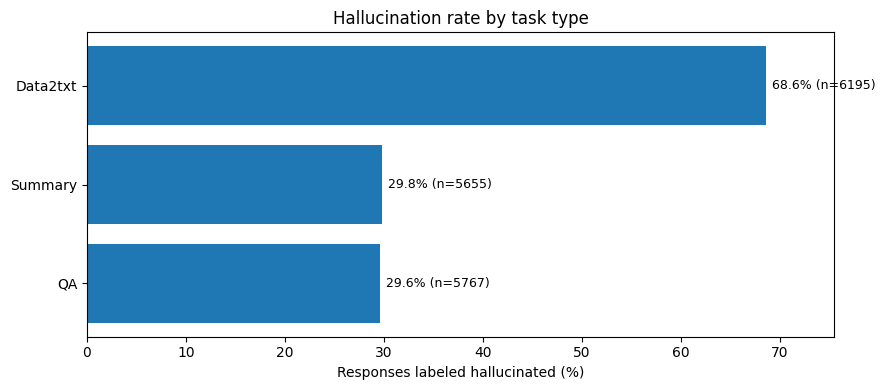

**Takeaway:** In this dataset, Data2txt has the highest observed hallucination rate (68.6%, n=6,195), while QA has the lowest (29.6%, n=5,767).

In [7]:
task_stats = df.groupby("task_type", dropna=False)["hallucinated"].agg(rate="mean", n="size").sort_values("rate", ascending=False)
fig, ax = plt.subplots(figsize=(9, max(4, len(task_stats)*0.65)))
ax.barh(task_stats.index.astype(str), task_stats["rate"] * 100)
ax.invert_yaxis()
ax.set(xlabel="Responses labeled hallucinated (%)", title="Hallucination rate by task type")
ax.set_xlim(0, max(5, task_stats["rate"].max()*110))
for i, (rate, count) in enumerate(zip(task_stats["rate"], task_stats["n"])):
    ax.text(rate*100+0.6, i, f"{rate:.1%} (n={count})", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR/"t11_hallucination_rate_by_task.png", dpi=180, bbox_inches="tight")
plt.show()
task_takeaway = (f"In this dataset, {task_stats.index[0]} has the highest observed "
                 f"hallucination rate ({task_stats.iloc[0].rate:.1%}, "
                 f"n={int(task_stats.iloc[0].n):,}), while {task_stats.index[-1]} "
                 f"has the lowest ({task_stats.iloc[-1].rate:.1%}, "
                 f"n={int(task_stats.iloc[-1].n):,}).")
display(Markdown("**Takeaway:** " + task_takeaway))

## 5. Box plot: Answer length by hallucination label
Each box shows the middle 50% of answer lengths, and the horizontal line within it marks the median. The plot hides individual outlier points for readability; the underlying data remain unchanged.


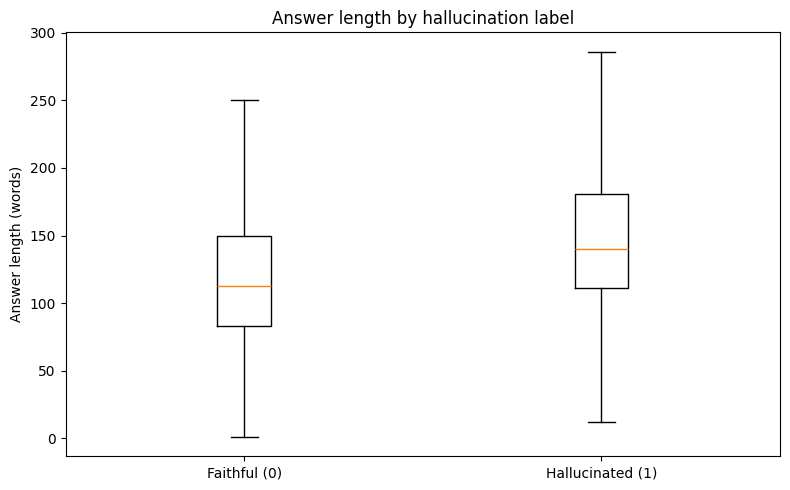

**Takeaway:** In this dataset, hallucinated responses have a higher median word count than faithful responses (140 versus 113 words, respectively).

In [8]:
faithful = pd.to_numeric(df.loc[df.hallucinated == 0, "answer_length"], errors="coerce").dropna()
halluc = pd.to_numeric(df.loc[df.hallucinated == 1, "answer_length"], errors="coerce").dropna()
if faithful.empty or halluc.empty:
    raise ValueError("Both labels (0 and 1) are required for the box plot.")
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([faithful, halluc], tick_labels=["Faithful (0)", "Hallucinated (1)"], showfliers=False)
ax.set(ylabel="Answer length (words)", title="Answer length by hallucination label")
fig.tight_layout()
fig.savefig(FIG_DIR/"t11_answer_length_boxplot.png", dpi=180, bbox_inches="tight")
plt.show()
med0, med1 = faithful.median(), halluc.median()
if med1 > med0:
    length_takeaway = (f"In this dataset, hallucinated responses have a higher median "
                       f"word count than faithful responses ({med1:.0f} versus "
                       f"{med0:.0f} words, respectively).")
elif med1 < med0:
    length_takeaway = (f"In this dataset, hallucinated responses have a lower median "
                       f"word count than faithful responses ({med1:.0f} versus "
                       f"{med0:.0f} words, respectively).")
else:
    length_takeaway = (f"In this dataset, hallucinated and faithful responses have "
                       f"the same median word count ({med1:.0f} words).")
display(Markdown("**Takeaway:** " + length_takeaway))

## 6. Heatmap: Correlations among engineered features
Pearson's correlation coefficient ranges from −1 to +1 and summarizes the direction and strength of a **linear association**. Correlation does **not** establish causation. This heatmap includes five engineered numerical features and excludes the response ID, target label, and one-hot-encoded model/task columns.


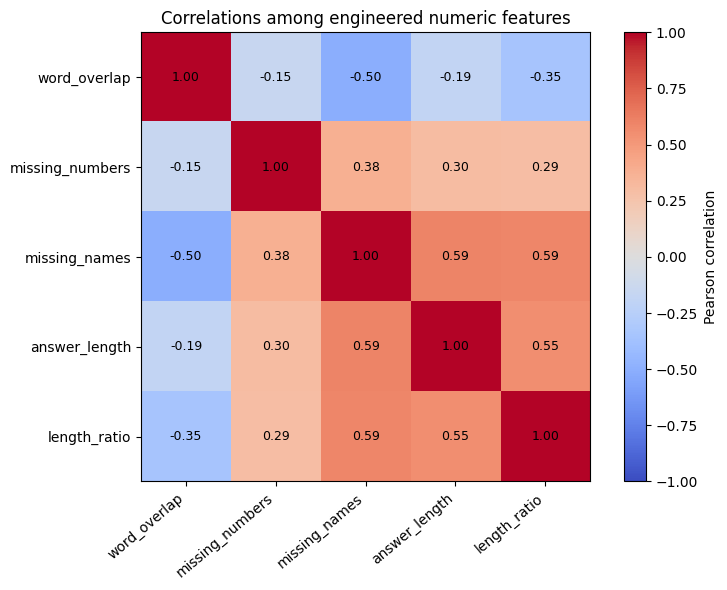

**Takeaway:** Among the five numeric features, the strongest absolute Pearson correlation is between missing_names and answer_length (r = 0.59); this does not establish causation.

In [9]:
numeric_features = ["word_overlap", "missing_numbers", "missing_names", "answer_length", "length_ratio"]
num = df[numeric_features].apply(pd.to_numeric, errors="coerce")
corr = num.corr(method="pearson")
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(numeric_features)), numeric_features, rotation=40, ha="right")
ax.set_yticks(np.arange(len(numeric_features)), numeric_features)
for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):
        val = corr.iloc[i, j]
        ax.text(j, i, "N/A" if np.isnan(val) else f"{val:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlations among engineered numeric features")
fig.tight_layout()
fig.savefig(FIG_DIR/"t11_feature_correlation_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().dropna()
if pairs.empty:
    correlation_takeaway = "No pairwise feature correlation could be estimated; inspect the feature distributions."
else:
    best_pair = pairs.abs().idxmax()
    r = corr.loc[best_pair[0], best_pair[1]]
    correlation_takeaway = (f"Among the five numeric features, the strongest absolute Pearson correlation is between "
                            f"{best_pair[0]} and {best_pair[1]} (Pearson r = {r:.2f}); this does not establish causation.")
display(Markdown("**Takeaway:** " + correlation_takeaway))

## 7. Export the four charts and takeaways
Review the chart labels and each takeaway. Then run the cell below to package the four PNG files and a Markdown summary for your GitHub pull request.


In [10]:
from zipfile import ZipFile
summary = "# T11 — Exploratory Chart Takeaways\n\n" + "\n".join([
    "1. **Hallucination rate by model:** " + model_takeaway,
    "2. **Hallucination rate by task:** " + task_takeaway,
    "3. **Answer length:** " + length_takeaway,
    "4. **Feature correlations:** " + correlation_takeaway,
]) + "\n\nThese are descriptive findings from the cleaned RAGTruth sample, not causal conclusions.\n"
Path("results/t11_takeaways.md").write_text(summary, encoding="utf-8")
archive = Path("t11_figures_and_takeaways.zip")
with ZipFile(archive, "w") as z:
    expected_figures = [
        "t11_hallucination_rate_by_model.png",
        "t11_hallucination_rate_by_task.png",
        "t11_answer_length_boxplot.png",
        "t11_feature_correlation_heatmap.png",
    ]
    missing_figures = [name for name in expected_figures if not (FIG_DIR / name).is_file()]
    if missing_figures:
        raise FileNotFoundError(f"Missing expected charts: {missing_figures}")
    for name in expected_figures:
        p = FIG_DIR / name
        z.write(p, arcname=str(p))
    z.write("results/t11_takeaways.md")
print(summary)
print("Created:", archive, "| figures:", len(expected_figures))
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    pass

# T11 — Exploratory Chart Takeaways

1. **Hallucination rate by model:** In this dataset, mistral-7B-instruct has the highest observed hallucination rate (67.0%, n=2,911), while gpt-3.5-turbo-0613 has the lowest (13.8%, n=2,906). These descriptive rates may be affected by differences in task composition.
2. **Hallucination rate by task:** In this dataset, Data2txt has the highest observed hallucination rate (68.6%, n=6,195), while QA has the lowest (29.6%, n=5,767).
3. **Answer length:** In this dataset, hallucinated responses have a higher median word count than faithful responses (140 versus 113 words, respectively).
4. **Feature correlations:** Among the five numeric features, the strongest absolute Pearson correlation is between missing_names and answer_length (r = 0.59); this does not establish causation.

These are descriptive findings from the cleaned RAGTruth sample, not causal conclusions.

Created: t11_figures_and_takeaways.zip | figures: 4
